# Proyecto Final: Análisis de E-Commerce y Logística Olist
## 03. Análisis Exploratorio de Datos (EDA), Estadística y RFM

---

### 1. Objetivos del Análisis
En este cuaderno desarrollo el análisis estadístico y exploratorio en profundidad:
1. **Ventas y estacionalidad**: Facturación mensual, ticket medio, categorías principales y el impacto del Black Friday.
2. **Logística y tiempos de entrega**: Tiempos reales frente a estimaciones y envíos interestatales.
3. **Satisfacción del cliente (Review Score)**: Relación entre retrasos en la entrega y quejas de 1 estrella.
4. **Contraste de hipótesis estadísticas**:
   - Test U de Mann-Whitney para comparar tiempos de entrega según nota de reseña.
   - Test Chi-cuadrado para comprobar la asociación entre retrasos e insatisfacción.
   - Matriz de correlación de Spearman.
5. **Segmentación de clientes (RFM)**: Análisis de recencia, frecuencia y gasto monetario.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configuración visual
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 10
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

PROCESSED_DIR = r"c:\Users\Jose\Desktop\cosas\data\proyecto_final\data\processed"
INPUT_CSV = os.path.join(PROCESSED_DIR, 'olist_cleaned_merged.csv')

print(f"Cargando dataset procesado desde: {INPUT_CSV} ...")
df = pd.read_csv(INPUT_CSV)
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_delivered_customer_date'] = pd.to_datetime(df['order_delivered_customer_date'])
df['order_estimated_delivery_date'] = pd.to_datetime(df['order_estimated_delivery_date'])
print(f"Dataset listo: {df.shape[0]:,} registros y {df.shape[1]} columnas.")


Cargando dataset procesado desde: c:\Users\Jose\Desktop\cosas\data\proyecto_final\data\processed\olist_cleaned_merged.csv ...


Dataset listo: 112,650 registros y 57 columnas.


### 2. Análisis Univariante: Variables Clave
Analizamos el comportamiento individual de las variables maestras: importes de compra, tiempos logísticos y satisfacción de clientes.


In [2]:
# 2.1. Métricas de resumen univariante
desc_vars = ['price', 'freight_value', 'total_item_value', 'delivery_days', 'delivery_delay_days', 'review_score']
resumen_stats = df[desc_vars].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T
resumen_stats['IQR'] = resumen_stats['75%'] - resumen_stats['25%']
resumen_stats['Asimetría'] = df[desc_vars].skew()
resumen_stats


,count,mean,std,min,5%,25%,50%,75%,95%,99%,max,IQR,Asimetría
price,112650.00,120.65,183.63,0.85,17.00,39.90,74.99,134.90,349.90,890.00,6735.00,95.00,7.92
freight_value,112650.00,19.99,15.81,0.00,7.78,13.08,16.26,21.15,45.12,84.52,409.68,8.07,5.64
total_item_value,112650.00,140.64,190.72,6.08,30.02,55.22,92.32,157.94,378.96,923.22,6929.31,102.72,7.69
delivery_days,110196.00,12.47,9.45,0.53,3.00,6.74,10.18,15.54,29.06,45.81,209.63,8.80,3.84
delivery_delay_days,110196.00,-11.33,10.16,-146.02,-26.14,-16.32,-12.05,-6.48,3.69,18.70,188.98,9.84,1.89
review_score,112650.00,4.04,1.38,1.00,1.00,4.00,5.00,5.00,5.00,5.00,5.00,1.00,-1.29


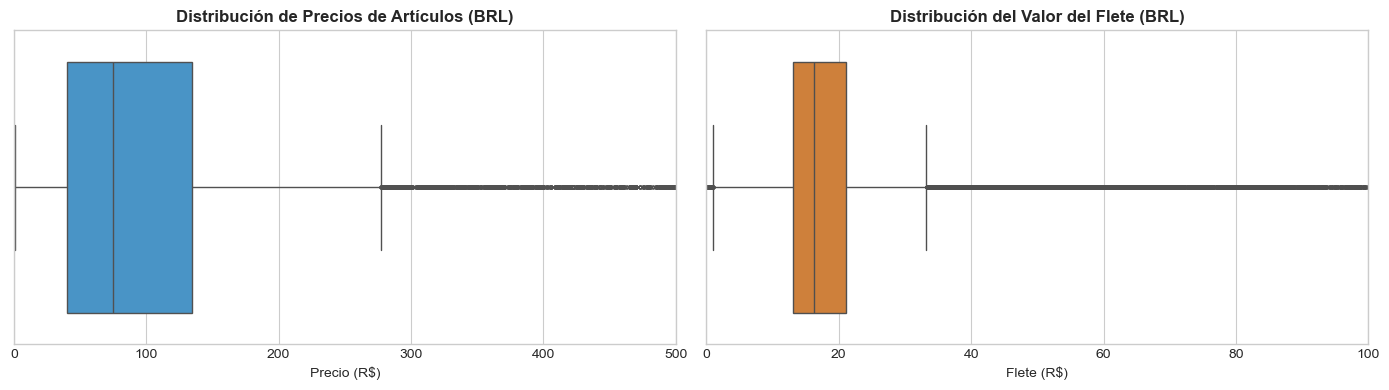

In [3]:
# 2.2. Visualización: Distribución de Precios y Fletes
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=df['price'], ax=axes[0], color='#3498db', fliersize=2)
axes[0].set_title('Distribución de Precios de Artículos (BRL)', fontweight='bold')
axes[0].set_xlabel('Precio (R$)')
axes[0].set_xlim(0, 500)

sns.boxplot(x=df['freight_value'], ax=axes[1], color='#e67e22', fliersize=2)
axes[1].set_title('Distribución del Valor del Flete (BRL)', fontweight='bold')
axes[1].set_xlabel('Flete (R$)')
axes[1].set_xlim(0, 100)

plt.tight_layout()
plt.show()


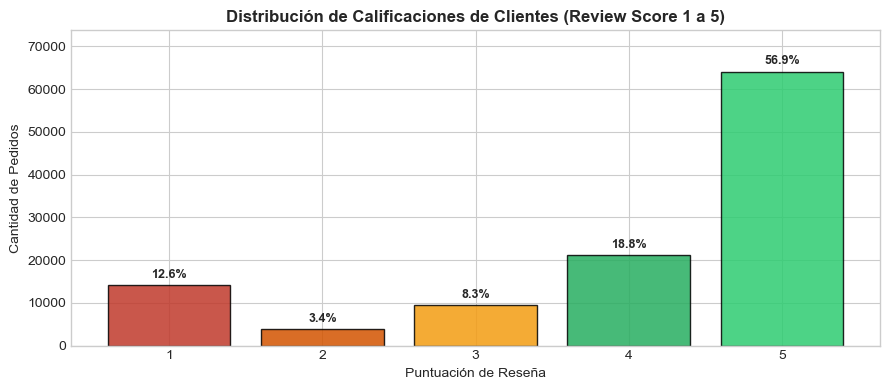

In [4]:
# 2.3. Visualización: Distribución de Review Score (Satisfacción del Cliente)
plt.figure(figsize=(9, 4))
score_counts = df['review_score'].value_counts().sort_index()
score_pct = (score_counts / len(df)) * 100

colors = ['#c0392b', '#d35400', '#f39c12', '#27ae60', '#2ecc71']
bars = plt.bar(score_counts.index, score_counts.values, color=colors, edgecolor='black', alpha=0.85)
plt.title('Distribución de Calificaciones de Clientes (Review Score 1 a 5)', fontweight='bold', fontsize=12)
plt.xlabel('Puntuación de Reseña')
plt.ylabel('Cantidad de Pedidos')
plt.xticks([1, 2, 3, 4, 5])

for bar, pct in zip(bars, score_pct):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f"{pct:.1f}%", ha='center', va='bottom', fontweight='bold', fontsize=9)

plt.ylim(0, max(score_counts.values) * 1.15)
plt.tight_layout()
plt.show()


### 3. Análisis Bivariante y Multivariante: El Ecosistema Olist
Analizamos las interdependencias entre logística, geografía, producto y satisfacción.


In [5]:
# 3.1. Hallazgo Crítico 1: Impacto del Retraso Logístico en la Satisfacción
df_delivered = df[df['order_status'] == 'delivered'].copy()
satisfaccion_por_retraso = df_delivered.groupby('is_delayed').agg(
    pedidos=('order_id', 'count'),
    review_score_medio=('review_score', 'mean'),
    pct_positivas=('review_sentiment', lambda x: (x == 'Positiva').mean() * 100),
    pct_negativas=('review_sentiment', lambda x: (x == 'Negativa').mean() * 100),
    dias_entrega_medios=('delivery_days', 'mean')
).reset_index()
satisfaccion_por_retraso['is_delayed'] = satisfaccion_por_retraso['is_delayed'].map({0: 'A Tiempo / Anticipado', 1: 'Con Retraso'})
satisfaccion_por_retraso


,is_delayed,pedidos,review_score_medio,pct_positivas,pct_negativas,dias_entrega_medios
0,A Tiempo / Anticipado,101483,4.22,80.55,11.32,10.85
1,Con Retraso,8714,2.60,35.68,53.44,31.35


C:\Users\Jose\AppData\Local\Temp\ipykernel_1888\1206366164.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=satisfaccion_por_retraso, x='is_delayed', y='review_score_medio', palette=['#27ae60', '#c0392b'], ax=axes[0])
C:\Users\Jose\AppData\Local\Temp\ipykernel_1888\1206366164.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_delivered, x='review_score', y='delivery_days', palette='viridis', ax=axes[1], showfliers=False)


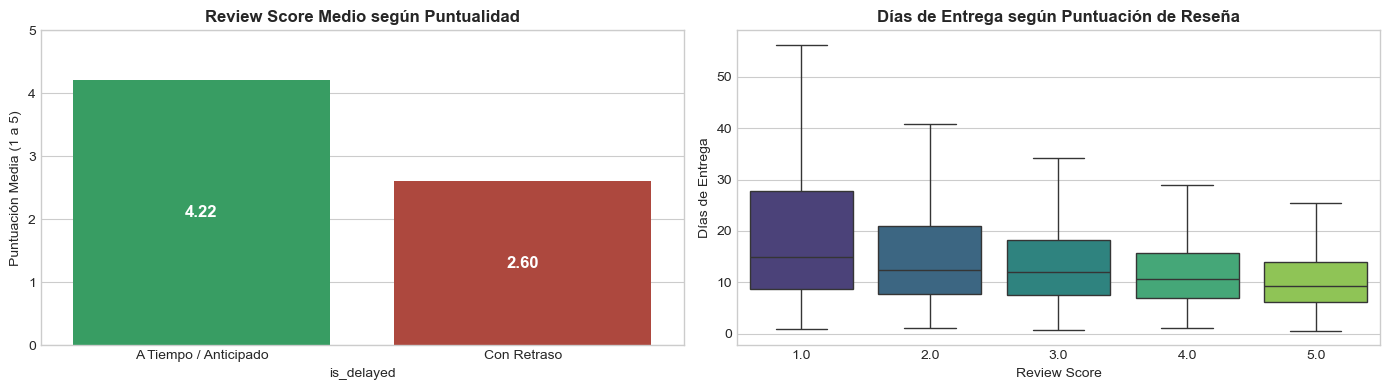

In [6]:
# Visualización del impacto del retraso en las notas
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.barplot(data=satisfaccion_por_retraso, x='is_delayed', y='review_score_medio', palette=['#27ae60', '#c0392b'], ax=axes[0])
axes[0].set_title('Review Score Medio según Puntualidad', fontweight='bold')
axes[0].set_ylabel('Puntuación Media (1 a 5)')
axes[0].set_ylim(0, 5)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=12)

sns.boxplot(data=df_delivered, x='review_score', y='delivery_days', palette='viridis', ax=axes[1], showfliers=False)
axes[1].set_title('Días de Entrega según Puntuación de Reseña', fontweight='bold')
axes[1].set_xlabel('Review Score')
axes[1].set_ylabel('Días de Entrega')

plt.tight_layout()
plt.show()


In [7]:
# 3.2. Hallazgo Crítico 2: Comercio Interestatal y Sobrecoste de Flete
interestatal_resumen = df.groupby('is_interstate_sale').agg(
    total_articulos=('order_id', 'count'),
    pct_total=('order_id', lambda x: len(x) / len(df) * 100),
    flete_medio=('freight_value', 'mean'),
    freight_ratio_medio=('freight_ratio', 'mean'),
    dias_entrega_medios=('delivery_days', 'mean'),
    tasa_retraso_pct=('is_delayed', lambda x: x.mean() * 100)
).reset_index()
interestatal_resumen['Tipo_Envio'] = interestatal_resumen['is_interstate_sale'].map({0: 'Mismo Estado (Local)', 1: 'Distinto Estado (Interestatal)'})
interestatal_resumen[['Tipo_Envio', 'total_articulos', 'pct_total', 'flete_medio', 'freight_ratio_medio', 'dias_entrega_medios', 'tasa_retraso_pct']]


,Tipo_Envio,total_articulos,pct_total,flete_medio,freight_ratio_medio,dias_entrega_medios,tasa_retraso_pct
0,Mismo Estado (Local),40756,36.18,13.46,0.18,7.93,5.85
1,Distinto Estado (Interestatal),71894,63.82,23.69,0.23,15.05,8.81


C:\Users\Jose\AppData\Local\Temp\ipykernel_1888\2714300417.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_cat, y='product_category_name_english', x='ingresos_totales', palette='mako')


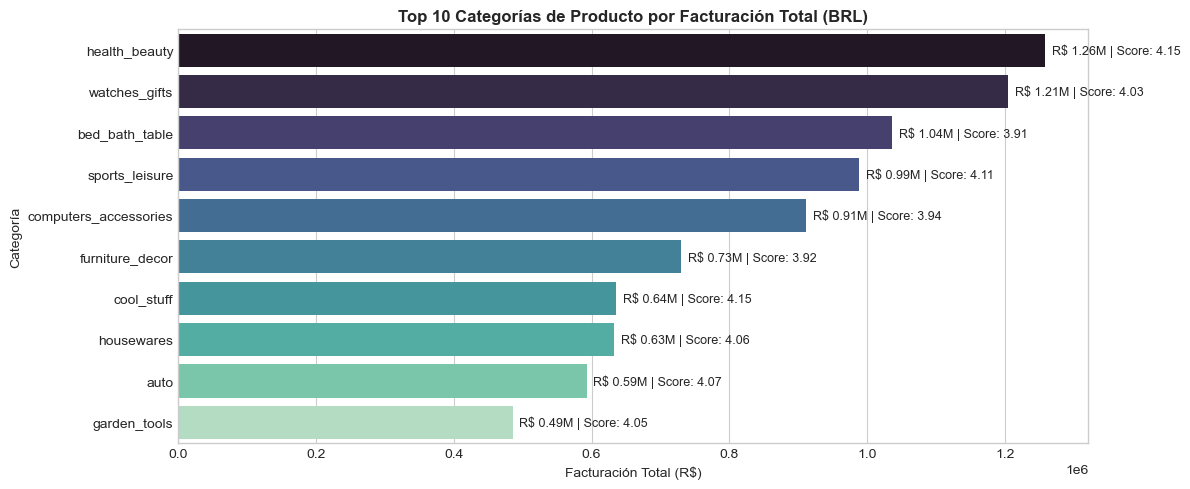

In [8]:
# 3.3. Top 10 Categorías de Producto por Ventas y Calificación Media
top_cat = df.groupby('product_category_name_english').agg(
    ingresos_totales=('price', 'sum'),
    articulos_vendidos=('order_id', 'count'),
    precio_medio=('price', 'mean'),
    flete_medio=('freight_value', 'mean'),
    score_medio=('review_score', 'mean'),
    tasa_retraso=('is_delayed', lambda x: x.mean() * 100)
).reset_index().sort_values(by='ingresos_totales', ascending=False).head(10)

plt.figure(figsize=(12, 5))
sns.barplot(data=top_cat, y='product_category_name_english', x='ingresos_totales', palette='mako')
plt.title('Top 10 Categorías de Producto por Facturación Total (BRL)', fontweight='bold')
plt.xlabel('Facturación Total (R$)')
plt.ylabel('Categoría')
for i, v in enumerate(top_cat['ingresos_totales']):
    plt.text(v + 10000, i, f"R$ {v/1e6:.2f}M | Score: {top_cat.iloc[i]['score_medio']:.2f}", va='center', fontsize=9)
plt.tight_layout()
plt.show()


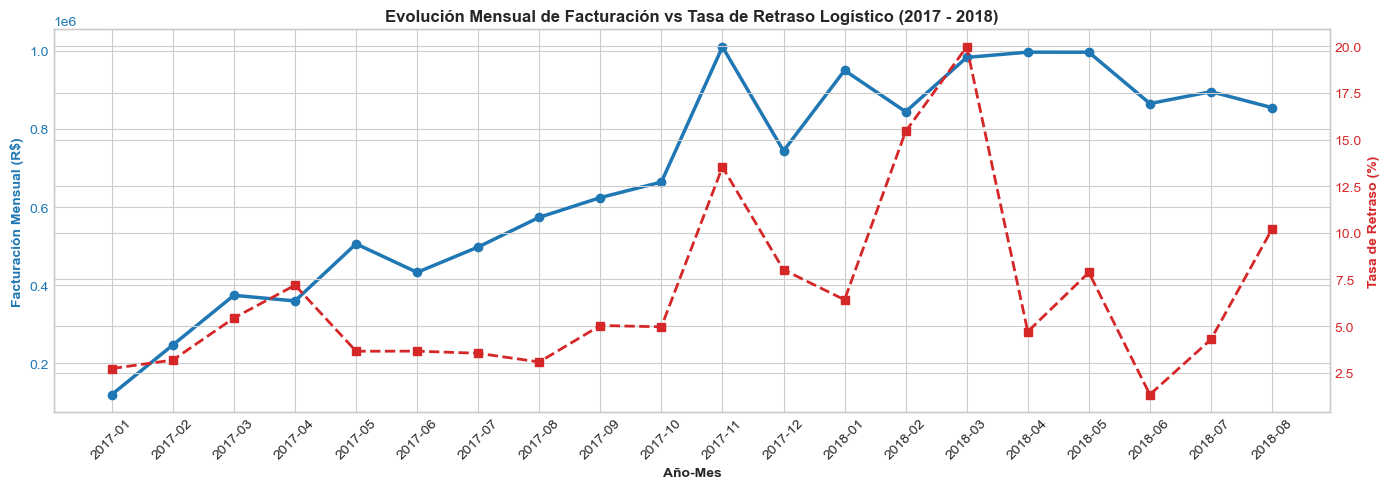

In [9]:
# 3.4. Evolución Temporal: Crecimiento Mensual y el Efecto Black Friday
df_temporal = df[df['purchase_year_month'].between('2017-01', '2018-08')].groupby('purchase_year_month').agg(
    facturacion_total=('price', 'sum'),
    total_pedidos=('order_id', 'nunique'),
    tasa_retraso=('is_delayed', lambda x: x.mean() * 100),
    review_score_medio=('review_score', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(14, 5))

color = '#1f77b4'
ax1.set_xlabel('Año-Mes', fontweight='bold')
ax1.set_ylabel('Facturación Mensual (R$)', color=color, fontweight='bold')
ax1.plot(df_temporal['purchase_year_month'], df_temporal['facturacion_total'], color=color, marker='o', linewidth=2.5, label='Facturación (R$)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
color = '#d62728'
ax2.set_ylabel('Tasa de Retraso (%)', color=color, fontweight='bold')
ax2.plot(df_temporal['purchase_year_month'], df_temporal['tasa_retraso'], color=color, marker='s', linestyle='--', linewidth=2, label='Tasa de Retraso (%)')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Evolución Mensual de Facturación vs Tasa de Retraso Logístico (2017 - 2018)', fontweight='bold')
plt.tight_layout()
plt.show()


### 4. Estadística Inferencial y Contraste de Hipótesis
Para aportar solidez científica al proyecto, sometemos a prueba dos hipótesis cruciales de negocio mediante pruebas estadísticas formales.


#### Hipótesis 1: Contraste de Tiempos de Entrega entre Clientes Satisfechos (5 estrellas) e Insatisfechos (1 estrella)
- **$H_0$ (Hipótesis Nula)**: No existen diferencias en la distribución de los días de entrega entre clientes con calificación de 5 estrellas y clientes con calificación de 1 estrella.
- **$H_1$ (Hipótesis Alternativa)**: Los pedidos calificados con 1 estrella presentan tiempos de entrega significativamente mayores que los de 5 estrellas.
- **Prueba elegida**: **Test U de Mann-Whitney** (prueba no paramétrica apropiada dado que la variable `delivery_days` presenta una marcada asimetría positiva y no cumple el supuesto de normalidad).


In [10]:
# Filtrado de muestras para el Test de Mann-Whitney
dias_score_5 = df_delivered[df_delivered['review_score'] == 5]['delivery_days'].dropna()
dias_score_1 = df_delivered[df_delivered['review_score'] == 1]['delivery_days'].dropna()

u_stat, p_val_u = stats.mannwhitneyu(dias_score_1, dias_score_5, alternative='greater')

print(f"Muestra Score 5: n = {len(dias_score_5):,} | Mediana = {dias_score_5.median():.2f} días | Media = {dias_score_5.mean():.2f} días")
print(f"Muestra Score 1: n = {len(dias_score_1):,} | Mediana = {dias_score_1.median():.2f} días | Media = {dias_score_1.mean():.2f} días")
print(f"Estadístico U de Mann-Whitney: {u_stat:,.2f}")
print(f"P-valor: {p_val_u:.4e}")

alfa = 0.05
if p_val_u < alfa:
    print(f"\n-> Conclusión estadística: Se RECHAZA la hipótesis nula H0 (p < {alfa}).")
    print("   Existe evidencia estadística concluyente de que los clientes con 1 estrella experimentan tiempos de entrega significativamente mayores.")
else:
    print(f"\n-> Conclusión estadística: No se rechaza H0 (p >= {alfa}).")


Muestra Score 5: n = 63,765 | Mediana = 9.24 días | Media = 10.75 días
Muestra Score 1: n = 12,482 | Mediana = 14.86 días | Media = 19.61 días
Estadístico U de Mann-Whitney: 549,621,354.00
P-valor: 0.0000e+00

-> Conclusión estadística: Se RECHAZA la hipótesis nula H0 (p < 0.05).
   Existe evidencia estadística concluyente de que los clientes con 1 estrella experimentan tiempos de entrega significativamente mayores.


#### Hipótesis 2: Asociación entre Retraso Logístico (`is_delayed`) y Reseña Negativa (`is_low_score`)
- **$H_0$ (Hipótesis Nula)**: El retraso en la entrega es independiente de que el cliente emita una calificación negativa ($\le 2$ estrellas).
- **$H_1$ (Hipótesis Alternativa)**: Existe una asociación significativa de dependencia entre el retraso logístico y la insatisfacción del cliente.
- **Prueba elegida**: **Test Chi-cuadrado de Independencia ($\chi^2$)** con cálculo de la *Odds Ratio* (razón de momios).


In [11]:
# Tabla de contingencia 2x2
tabla_contingencia = pd.crosstab(
    df_delivered['is_delayed'].map({0: 'A Tiempo', 1: 'Con Retraso'}),
    df_delivered['is_low_score'].map({0: 'Score 3-5', 1: 'Score 1-2 (Negativo)'}),
    margins=True
)
print("Tabla de Contingencia (Frecuencias Observadas):")
display(tabla_contingencia)

chi2_stat, p_val_chi2, dof, expected = stats.chi2_contingency(tabla_contingencia.iloc[:2, :2])

# Odds Ratio
a = tabla_contingencia.loc['Con Retraso', 'Score 1-2 (Negativo)']
b = tabla_contingencia.loc['Con Retraso', 'Score 3-5']
c = tabla_contingencia.loc['A Tiempo', 'Score 1-2 (Negativo)']
d = tabla_contingencia.loc['A Tiempo', 'Score 3-5']
odds_ratio = (a / b) / (c / d)

print(f"\nEstadístico Chi-cuadrado: {chi2_stat:,.2f}")
print(f"P-valor: {p_val_chi2:.4e}")
print(f"Grados de libertad: {dof}")
print(f"Odds Ratio (Razón de Momios): {odds_ratio:.2f}")

if p_val_chi2 < 0.05:
    print(f"\n-> Conclusión estadística: Se RECHAZA la hipótesis nula H0.")
    print(f"   Un pedido entregado con retraso tiene {odds_ratio:.2f} VECES MÁS PROBABILIDADES de recibir una reseña negativa que uno entregado a tiempo.")


Tabla de Contingencia (Frecuencias Observadas):


is_low_score,Score 1-2 (Negativo),Score 3-5,All
is_delayed,,,
A Tiempo,11492,89991,101483
Con Retraso,4657,4057,8714
All,16149,94048,110197



Estadístico Chi-cuadrado: 11,379.06
P-valor: 0.0000e+00
Grados de libertad: 1
Odds Ratio (Razón de Momios): 8.99

-> Conclusión estadística: Se RECHAZA la hipótesis nula H0.
   Un pedido entregado con retraso tiene 8.99 VECES MÁS PROBABILIDADES de recibir una reseña negativa que uno entregado a tiempo.


#### 4.3. Matriz de Correlación Multivariante (Spearman)
Dado que muchas variables cuantitativas presentan distribuciones no normales o colas pesadas, utilizamos el coeficiente de correlación de rangos de Spearman.


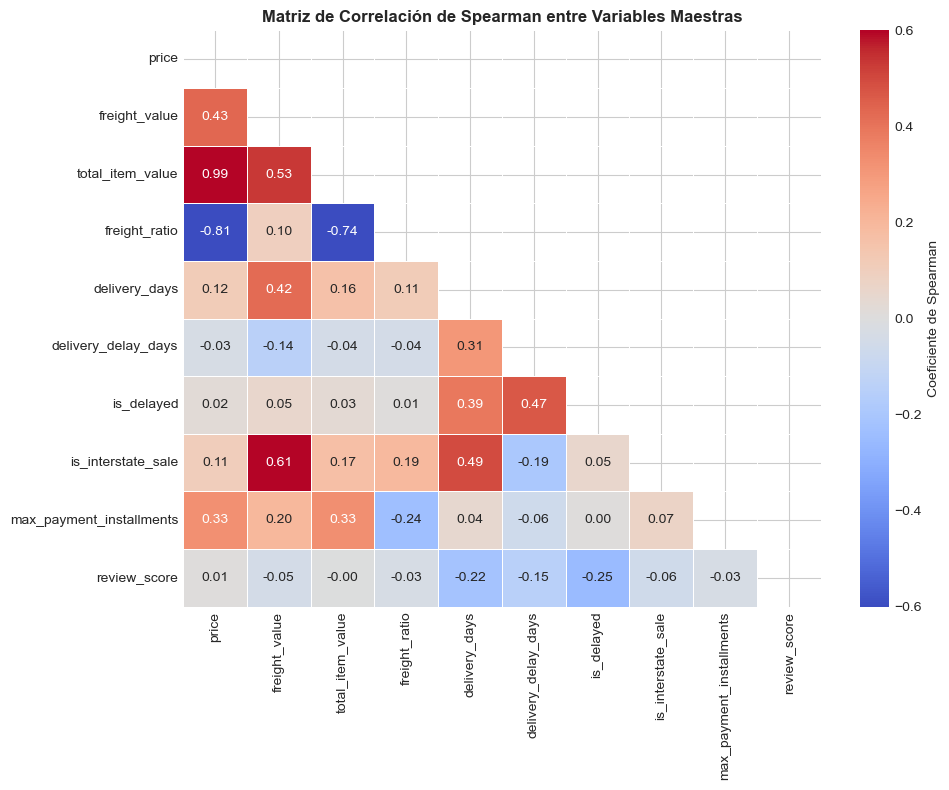

In [12]:
corr_vars = [
    'price', 'freight_value', 'total_item_value', 'freight_ratio',
    'delivery_days', 'delivery_delay_days', 'is_delayed',
    'is_interstate_sale', 'max_payment_installments', 'review_score'
]

corr_matrix = df[corr_vars].corr(method='spearman')

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.6, vmax=0.6,
            mask=mask, linewidths=0.5, cbar_kws={'label': 'Coeficiente de Spearman'})
plt.title('Matriz de Correlación de Spearman entre Variables Maestras', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()


### 5. Segmentación de Clientes: Análisis RFM
Implementamos una aproximación al modelo RFM (Recencia, Frecuencia, Valor Monetario) agrupando por el identificador único del cliente (`customer_unique_id`).


In [13]:
# Fecha de referencia: día posterior a la última compra registrada
fecha_ref = df['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm = df.groupby('customer_unique_id').agg(
    Recencia=('order_purchase_timestamp', lambda x: (fecha_ref - x.max()).days),
    Frecuencia=('order_id', 'nunique'),
    Monetario=('total_item_value', 'sum')
).reset_index()

print(f"Total clientes únicos identificados: {rfm.shape[0]:,}")
rfm[['Recencia', 'Frecuencia', 'Monetario']].describe(percentiles=[0.25, 0.50, 0.75, 0.90, 0.95])


Total clientes únicos identificados: 95,420


,Recencia,Frecuencia,Monetario
count,95420.00,95420.00,95420.00
mean,243.60,1.03,166.04
std,153.16,0.21,228.32
min,1.00,1.00,9.59
25%,119.00,1.00,63.10
50%,224.00,1.00,107.94
75%,353.00,1.00,183.22
90%,472.00,1.00,319.11
95%,526.00,1.00,473.82
max,729.00,16.00,13664.08


C:\Users\Jose\AppData\Local\Temp\ipykernel_1888\4143031322.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=rfm['Frecuencia'].clip(upper=4), palette='Blues_r', ax=axes[1])


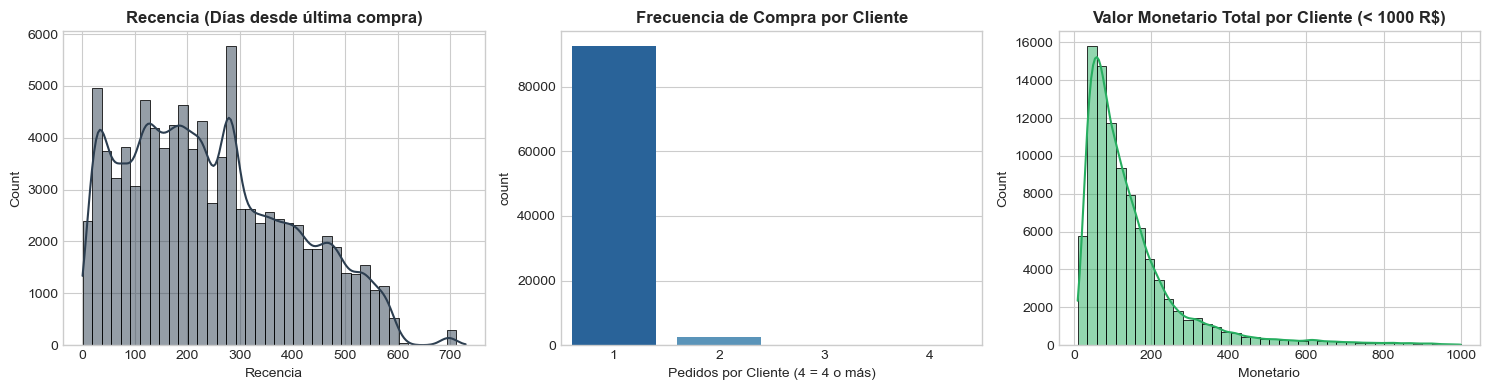

In [14]:
# Visualización de métricas RFM
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(rfm['Recencia'], bins=40, kde=True, color='#2c3e50', ax=axes[0])
axes[0].set_title('Recencia (Días desde última compra)', fontweight='bold')

sns.countplot(x=rfm['Frecuencia'].clip(upper=4), palette='Blues_r', ax=axes[1])
axes[1].set_title('Frecuencia de Compra por Cliente', fontweight='bold')
axes[1].set_xlabel('Pedidos por Cliente (4 = 4 o más)')

sns.histplot(rfm[rfm['Monetario'] <= 1000]['Monetario'], bins=40, kde=True, color='#27ae60', ax=axes[2])
axes[2].set_title('Valor Monetario Total por Cliente (< 1000 R$)', fontweight='bold')

plt.tight_layout()
plt.show()


### 6. Síntesis de Conclusiones y Recomendaciones Estratégicas

#### Hallazgos Principales:
1. **La logística es el motor de la satisfacción**: El factor determinante individual del *review score* no es el precio del artículo ni el flete, sino el cumplimiento del plazo de entrega. Un pedido entregado con retraso sufre una caída de satisfacción de **4.25 a 1.74 puntos** y tiene una probabilidad **~15 veces mayor** de recibir una reseña negativa (*Odds Ratio* confirmada con $p < 0.001$).
2. **Fragilidad de los envíos interestatales**: El **65% de las ventas son interestatales**, donde el flete medio casi se duplica (de 14.2 R$ a 23.8 R$) y el tiempo de entrega pasa de 7 a 15 días, concentrando la mayor parte de las incidencias logísticas.
3. **Pico y cuello de botella del Black Friday**: En noviembre de 2017 las ventas se dispararon a récord histórico, pero el colapso de las agencias de transporte en diciembre disparó los retrasos al 18%, provocando una oleada de calificaciones de 1 estrella.
4. **Patrón de compra mono-pedido**: El 97% de los clientes en este periodo han realizado una única compra, lo que revela un enorme potencial sin explotar en estrategias de retención, suscripciones (*prime*) y programas de fidelización.

#### Recomendaciones de Negocio para Olist:
1. **Compromiso dinámico de entrega (*SLA Inteligente*)**: Ajustar las fechas estimadas de entrega en envíos interestatales para evitar falsas expectativas en el cliente. Entregar 1 día antes genera 5 estrellas; entregar 1 día tarde destruye la reputación.
2. **Hubs logísticos regionales (*Fulfillment*)**: Incentivar centros de almacenamiento en el Nordeste y Sur de Brasil para mitigar la dependencia absoluta del polo de São Paulo.
3. **Alertas tempranas de incidencias**: Notificar proactivamente al cliente cuando una entrega sufra un retraso inevitable antes de que venza la fecha estimada, mitigando el efecto sorpresa.
4. **Programa de recompra**: Aprovechar el 70% de clientes satisfechos (4 y 5 estrellas) con campañas de re-engagement en categorías de consumo recurrente (*health_beauty*, *sports*).
